# Air Quality Analytics Using Apache Spark — Reliable Run Notebook

This notebook reuses your existing, already-working `run_analysis.py` and displays its generated outputs. It also configures the notebook process's Java/Python environment before launching the script.

**Why this setup exists:** VS Code's Jupyter kernel may not inherit the same environment as your PowerShell terminal. In particular, Spark needs `JAVA_HOME`, and the script must be launched with the same virtual-environment Python interpreter.

Keep this notebook beside `run_analysis.py` in your `Air_Quality_Spark_Project` folder. Your existing `data/` and `outputs/` folders should remain in place.


In [1]:
from pathlib import Path
import os
import sys
import shutil
import subprocess
import re

ROOT = Path.cwd()
SCRIPT = ROOT / "run_analysis.py"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

print("Notebook Python:", sys.executable)
print("Project folder:", ROOT)
print("Analysis script found:", SCRIPT.exists())

if not SCRIPT.exists():
    raise FileNotFoundError(
        f"Could not find {SCRIPT}. Open this notebook from the project folder "
        "that contains run_analysis.py."
    )


Notebook Python: c:\Users\Shuhani Goyal\OneDrive\Documents\Desktop\Air_Quality_Spark_Project\.venv\Scripts\python.exe
Project folder: c:\Users\Shuhani Goyal\OneDrive\Documents\Desktop\Air_Quality_Spark_Project
Analysis script found: True


## 1. Configure Java and Python for this notebook

This cell tries to discover the actual Java installation directory from the Java executable. It does not permanently change Windows settings; it only configures this notebook's child process.

In [2]:
# Locate Java from the current kernel environment.
java_cmd = shutil.which("java")
if not java_cmd:
    # Common Oracle launcher location on Windows.
    oracle_launcher = Path(r"C:\Program Files\Common Files\Oracle\Java\javapath\java.exe")
    if oracle_launcher.exists():
        java_cmd = str(oracle_launcher)

if not java_cmd:
    raise RuntimeError(
        "Java could not be found by the notebook kernel. "
        "Open the VS Code terminal, run `java -version`, and share the result."
    )

# Ask Java itself where its real runtime is located.
probe = subprocess.run(
    [java_cmd, "-XshowSettings:properties", "-version"],
    capture_output=True, text=True, errors="replace"
)
java_home = None
for line in (probe.stdout + "\n" + probe.stderr).splitlines():
    match = re.match(r"\s*java\.home\s*=\s*(.+?)\s*$", line)
    if match:
        java_home = match.group(1)
        break

if not java_home:
    # Fallback: resolve java.exe's path if possible.
    try:
        resolved = Path(java_cmd).resolve()
        if resolved.parent.name.lower() == "bin":
            java_home = str(resolved.parent.parent)
    except Exception:
        pass

if not java_home or not Path(java_home).exists():
    raise RuntimeError(
        f"Found Java launcher at {java_cmd}, but couldn't determine JAVA_HOME. "
        "Please share the output of `java -XshowSettings:properties -version`."
    )

env = os.environ.copy()
env["JAVA_HOME"] = java_home
env["PYSPARK_PYTHON"] = sys.executable
env["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Ensure Windows system utilities and Java are available to child processes.
path_entries = [str(Path(java_home) / "bin"), r"C:\Windows\System32", env.get("PATH", "")]
env["PATH"] = os.pathsep.join(p for p in path_entries if p)

print("Java launcher:", java_cmd)
print("JAVA_HOME for this run:", env["JAVA_HOME"])
print("Python used for Spark:", env["PYSPARK_PYTHON"])
print("Java version probe exit code:", probe.returncode)
print("Environment configured for this notebook run.")


Java launcher: C:\Program Files\Common Files\Oracle\Java\javapath\java.EXE
JAVA_HOME for this run: C:\Program Files\Java\jdk-25.0.2
Python used for Spark: c:\Users\Shuhani Goyal\OneDrive\Documents\Desktop\Air_Quality_Spark_Project\.venv\Scripts\python.exe
Java version probe exit code: 0
Environment configured for this notebook run.


## 2. Run the existing analysis script

This launches your existing script with the notebook's Python interpreter and the environment configured above. It does not rewrite your script.

In [3]:
result = subprocess.run(
    [sys.executable, str(SCRIPT)],
    cwd=str(ROOT),
    env=env,
    capture_output=True,
    text=True,
    errors="replace"
)

print("----- SCRIPT OUTPUT -----")
print(result.stdout if result.stdout else "(No standard output)")
if result.stderr:
    print("\\n----- WARNINGS / ERRORS -----")
    print(result.stderr[-12000:])

if result.returncode != 0:
    raise RuntimeError(
        f"run_analysis.py exited with code {result.returncode}. "
        "The full error is printed above; send me that output if it still fails."
    )
else:
    print("\\nAnalysis script completed successfully.")


----- SCRIPT OUTPUT -----
Missing Python executable 'c:\Users\Shuhani Goyal\OneDrive\Documents\Desktop\Air_Quality_Spark_Project\.venv\Scripts\python.exe', defaulting to 'C:\Users\Shuhani Goyal\OneDrive\Documents\Desktop\Air_Quality_Spark_Project\.venv\Lib\site-packages\pyspark\bin\..' for SPARK_HOME environment variable. Please install Python or specify the correct Python executable in PYSPARK_DRIVER_PYTHON or PYSPARK_PYTHON environment variable to detect SPARK_HOME safely.
AIR QUALITY ANALYTICS â€” RUN SUMMARY
Input rows read: 9471
Rows after duplicate removal: 9358
Pollutant columns analyzed: CO_GT, NMHC_GT, C6H6_GT, NOx_GT, NO2_GT
Spark master: local[*]
Execution mode: local Spark (single machine; not a multi-node cluster)

Pollutant mean values:
  CO (mg/mÂ³): 2.1527
  NMHC (Âµg/mÂ³): 218.8118
  Benzene (Âµg/mÂ³): 10.0831
  NOx (ppb): 246.8967
  NO2 (Âµg/mÂ³): 113.0913

Interpretation: use exported aggregation tables and charts to report observed patterns.
Do not claim causation; 

## 3. Check the generated files

This cell lists files actually present in `outputs/`. If the script ran successfully, you should see the summary CSVs and PNG charts here.

In [4]:
files = sorted(p for p in OUT.iterdir() if p.is_file())
if not files:
    print("No output files found yet.")
else:
    for p in files:
        print(f"{p.name} — {p.stat().st_size:,} bytes")


cleaned_air_quality.csv — 1,088,990 bytes
hourly_co_pattern.png — 58,701 bytes
hourly_pattern.csv — 2,349 bytes
monthly_co_pattern.png — 49,918 bytes
monthly_pattern.csv — 1,049 bytes
pollutant_averages.png — 50,140 bytes
pollutant_summary.csv — 405 bytes
run_summary.txt — 668 bytes


## 4. Display summary and charts

The tables and images are loaded from the output files generated by the script, not from hard-coded example data.

,CO_GT_mean,CO_GT_valid_count,CO_GT_missing_count,NMHC_GT_mean,NMHC_GT_valid_count,NMHC_GT_missing_count,C6H6_GT_mean,C6H6_GT_valid_count,C6H6_GT_missing_count,NOx_GT_mean,NOx_GT_valid_count,NOx_GT_missing_count,NO2_GT_mean,NO2_GT_valid_count,NO2_GT_missing_count
0,2.15275,7674,1684,218.811816,914,8444,10.083105,8991,367,246.896735,7718,1640,113.091251,7715,1643


\nhourly_pattern.csv


,hour,CO_GT_mean,NMHC_GT_mean,C6H6_GT_mean,NOx_GT_mean,NO2_GT_mean
0,0,1.786018,103.128205,7.684140,190.419643,103.321429
1,1,1.467802,76.973684,5.991711,157.332335,90.502994
2,2,1.099063,61.868421,4.379467,118.581325,75.436747
3,3,0.888462,52.972973,3.379255,114.576923,80.115385
4,4,0.758659,40.189189,2.916711,81.153614,58.620482
5,5,0.712934,40.078947,3.068435,86.801802,59.612613
6,6,0.921562,71.447368,4.756117,125.691617,71.742515
7,7,1.810903,235.605263,10.398936,224.625749,94.709581
8,8,2.823750,421.552632,15.894149,344.723404,121.268293
9,9,2.972477,381.236842,14.760317,361.326347,130.876877


\nmonthly_pattern.csv


,month,CO_GT_mean,NMHC_GT_mean,C6H6_GT_mean,NOx_GT_mean,NO2_GT_mean
0,1,2.135059,NaN,9.024597,349.819718,134.781690
1,2,2.096229,NaN,7.500839,315.043614,160.694704
2,3,2.144079,171.604423,9.219393,243.184275,123.285831
3,4,2.142931,256.671937,9.708333,145.638743,98.710297
4,5,1.940034,275.000000,10.219041,122.132107,93.148829
5,6,1.900000,NaN,10.595748,122.064715,94.084877
6,7,1.784946,NaN,10.599462,126.754213,104.120956
7,8,1.280084,NaN,6.993669,75.868526,70.097804
8,9,2.164209,NaN,11.554558,280.572072,108.047297
9,10,2.724682,NaN,13.525303,338.007752,89.775194


pollutant_averages.png


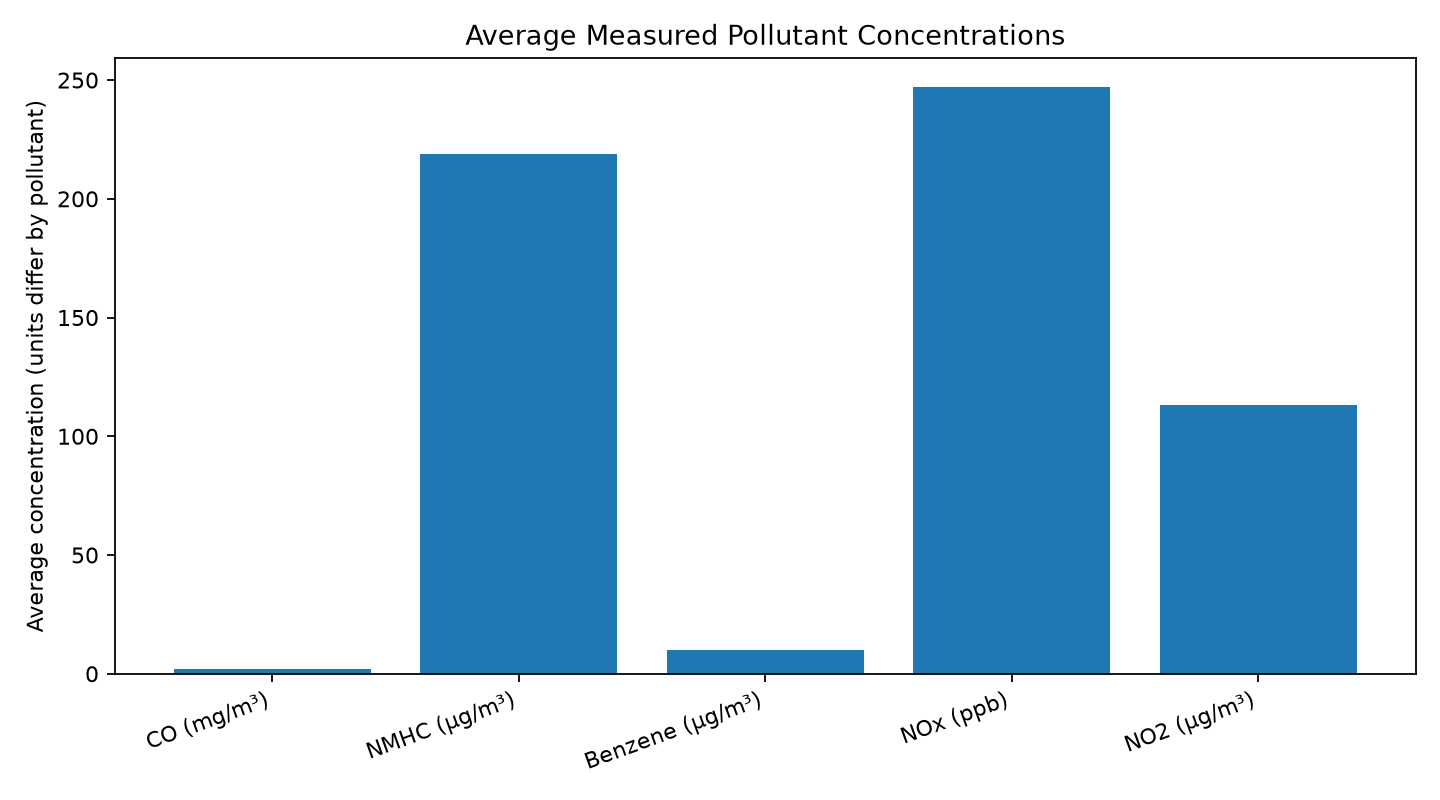

hourly_co_pattern.png


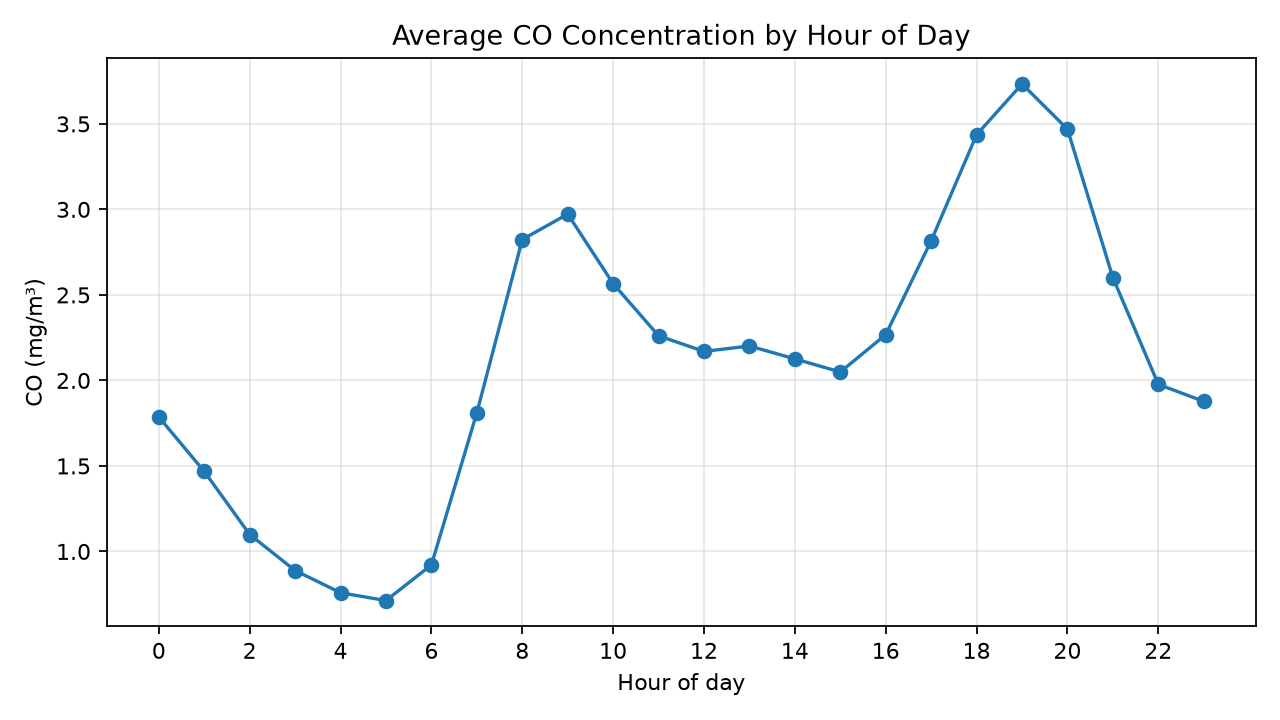

monthly_co_pattern.png


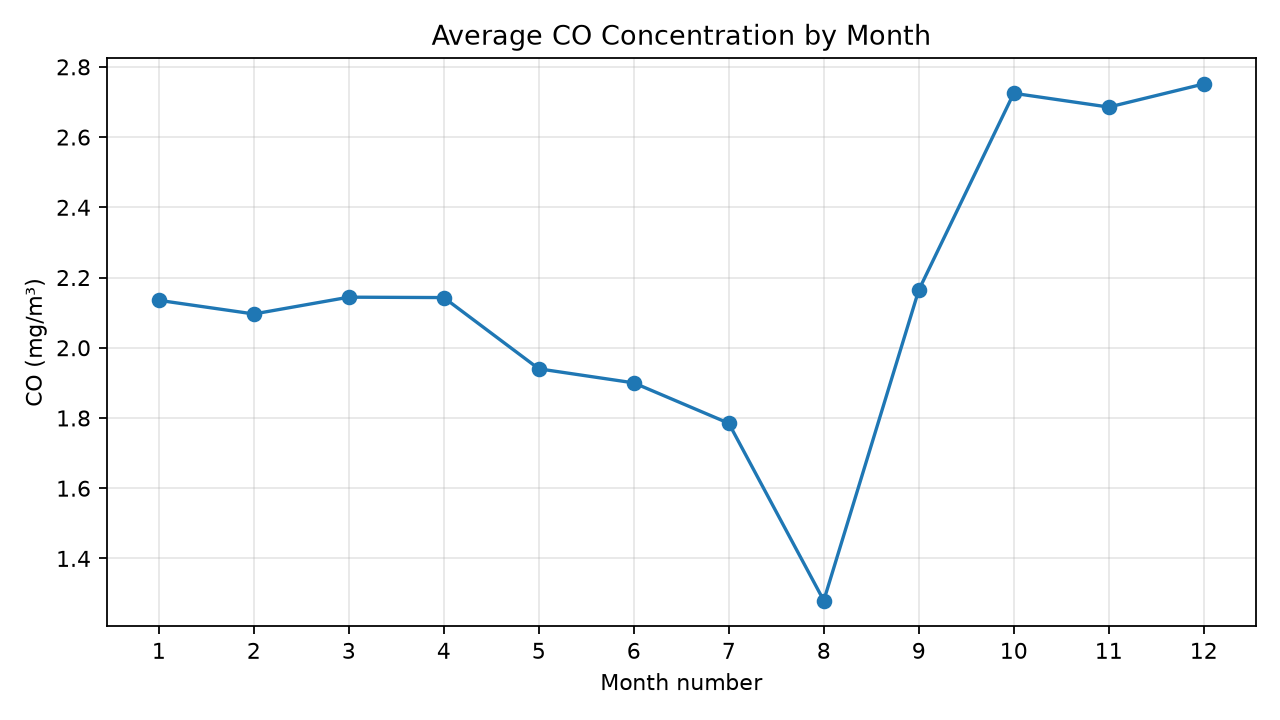

In [5]:
import pandas as pd
from IPython.display import display, Image

summary_file = OUT / "pollutant_summary.csv"
if summary_file.exists():
    display(pd.read_csv(summary_file))
else:
    print("pollutant_summary.csv not found.")

for name in ["hourly_pattern.csv", "monthly_pattern.csv"]:
    file = OUT / name
    if file.exists():
        print(f"\\n{name}")
        display(pd.read_csv(file).head(30))

for name in ["pollutant_averages.png", "hourly_co_pattern.png", "monthly_co_pattern.png"]:
    file = OUT / name
    if file.exists():
        print(name)
        display(Image(filename=str(file)))
    else:
        print(f"Chart not found yet: {name}")


## 5. What the results mean

Use the generated tables and charts to describe observed pollutant averages and hourly/monthly patterns. Do not claim that time of day or month caused the changes; the dataset is observational and historical. Pollutants use different measurement units, so their raw averages should not be compared as a shared scale.

**Execution note:** Spark runs locally on this computer; `local[*]` is not a multi-node cluster.